# EGT309 Project – EDA
### Predicting `maintenance_required` from machine sensor readings

**Goal:**
1. Understand every column (types, ranges, nulls, invalid values, outliers)
2. Decide on cleaning and imputation methods, and justify the decision
3. Find which features relate to `maintenance_required`
4. Record the decisions that the `src/` pipeline will implement

In [ ]:
# Install required packages
%pip install pandas numpy matplotlib seaborn scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ------------------------------------- -- 10.0/10.8 MB 47.8 MB/s eta 0:00:01
   ---------------------------------------- 10.8/10.8 MB 42.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------  12.3/12.6 MB 70.1 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 60.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 9.3/9.3 MB 52.8 MB/s eta 0:00:00
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ------------------------- -------------- 5.2/8.3 MB 79.1 MB/s eta 0:00:01
   

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
# Import all the necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

# Import sklearn libraries for model building and evaluation
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
# Classification metrics, ROC AUC, recall, and F1 score
from sklearn.metrics import classification_report, roc_auc_score, recall_score, f1_score

# Set pandas display options for better readability
pd.options.display.max_columns = 50
pd.options.display.float_format = "{:.3f}".format

# Define constants
DATA_PATH = "data/proj_machine_readings.csv"
TARGET = "maintenance_required"
SENSORS = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]
DERIVED = ["machine_status", "anomaly_flag", "predicted_remaining_life", "failure_type", "downtime_risk"]
RANDOM_STATE = 42

# Class 0 (no maintenance) = blue, class 1 (maintenance) = orange
PALETTE = {0: "#2a78d2", 1: "#eb6831"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

In [8]:
# Define a function to calculate the target rate for each bin (range of values for temperature)
def target_rate_by_bin(df, col, bins, target=TARGET):
    """Return the row count and % of maintenance_required=1 for each bin of `col`."""
    binned = pd.cut(df[col], bins=bins)
    out = df.groupby(binned, observed=True)[target].agg(rows="size", maintenance_rate="mean")
    out["maintenance_rate"] = (out["maintenance_rate"] * 100).round(1)
    return out

# Define a function to plot an overlaid histogram of a column split by the target class
def plot_hist_by_target(df, col, ax, bins=60, title=None):
    """Overlaid histogram of `col`, split by the target class."""
    sns.histplot(data=df, x=col, hue=TARGET, bins=bins, palette=PALETTE,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(title or f"{col} by {TARGET}")

## 1. Load the data & initial understanding

In [9]:
# Load the dataset and display its shape and first few rows
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(100000, 13)


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.650,79.960,3.730,2.160,1,0,106,Normal,0.000,0
1,2025-01-01 00:01:00,29,68.190,57.280,35.940,3.640,0.690,1,0,320,Normal,0.000,0
2,2025-01-01 00:02:00,15,98.940,50.200,72.060,1.000,2.490,1,1,19,Normal,1.000,1
3,2025-01-01 00:03:00,43,90.910,37.650,30.340,3.150,4.960,1,1,10,Normal,1.000,1
4,2025-01-01 00:04:00,8,72.320,40.690,56.710,2.680,0.630,2,0,65,Vibration Issue,0.000,1


In [10]:
# Display the DataFrame information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   timestamp                 100000 non-null  str    
 1   machine_id                100000 non-null  int64  
 2   temperature               86000 non-null   float64
 3   vibration                 100000 non-null  float64
 4   humidity                  100000 non-null  float64
 5   pressure                  100000 non-null  float64
 6   energy_consumption        100000 non-null  float64
 7   machine_status            100000 non-null  int64  
 8   anomaly_flag              100000 non-null  int64  
 9   predicted_remaining_life  100000 non-null  int64  
 10  failure_type              100000 non-null  str    
 11  downtime_risk             100000 non-null  float64
 12  maintenance_required      100000 non-null  int64  
dtypes: float64(6), int64(5), str(2)
memory usage: 9.9 MB


In [11]:
# Display summary statistics for all columns (transposed for better readability)
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,100000,100000,2025-01-01 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
machine_id,100000.000,NaN,NaN,NaN,25.499,14.389,1.000,13.000,25.000,38.000,50.000
temperature,86000.000,NaN,NaN,NaN,75.034,10.036,35.550,68.280,75.090,81.780,121.940
vibration,100000.000,NaN,NaN,NaN,43.324,29.134,-106.980,37.220,48.635,59.250,113.800
humidity,100000.000,NaN,NaN,NaN,54.995,14.438,30.000,42.520,54.980,67.500,80.000
pressure,100000.000,NaN,NaN,NaN,3.000,1.152,1.000,2.000,3.010,4.000,5.000
energy_consumption,100000.000,NaN,NaN,NaN,2.747,1.298,0.500,1.630,2.740,3.870,5.000
machine_status,100000.000,NaN,NaN,NaN,1.002,0.446,0.000,1.000,1.000,1.000,2.000
anomaly_flag,100000.000,NaN,NaN,NaN,0.089,0.285,0.000,0.000,0.000,0.000,1.000
predicted_remaining_life,100000.000,NaN,NaN,NaN,234.269,150.063,1.000,97.000,230.000,365.000,499.000


In [12]:
# Check for null values and duplicated rows
print("Null values per column:")
display(df.isna().sum()[df.isna().sum() > 0])
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated rows ignoring timestamp:", df.drop(columns="timestamp").duplicated().sum())

Null values per column:


temperature    14000
dtype: int64

Fully duplicated rows: 0
Duplicated rows ignoring timestamp: 0


In [ ]:
# Check whether the same machine has multiple readings at the same timestamp
df.duplicated(subset=["machine_id", "timestamp"]).sum()

np.int64(0)

<mark>Initial insights from `.info()` / `.describe()`:</mark>

1. **100,000 rows × 13 columns**, with no duplicate rows (even ignoring the timestamp), so no de-duplication is needed.
2. **`temperature` is the only column with nulls: 14,000 (14%).** That is too many to drop (the notes suggest dropping only if around 5% or less), so it has to be **imputed** (Section 4.1).
3. **`timestamp` is stored as a string.** It must be parsed to `datetime` before it can be used.
4. **`machine_id` is stored as int**, but the problem statement says it is a category label, not a quantity. "Machine 40 > machine 20" means nothing, so it must not be treated as a number.
5. **`vibration` has a negative minimum (−106.98).** Vibration level in mm/s is a magnitude and cannot be negative, so these are **invalid values** (Section 4.2).
6. **`downtime_risk` is a float** but its 25/50/75 percentiles are all 0 and its max is 1, so it looks almost binary (Section 5.5).
7. The `humidity` (30–80), `pressure` (1–5) and `energy_consumption` (0.5–5) ranges are all physically plausible, with no out-of-range values.

## 2. Target column: `maintenance_required`

,count,percent
maintenance_required,,
0,80303,80.300
1,19697,19.700


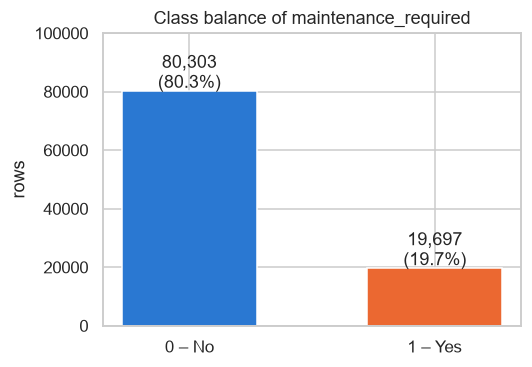

In [14]:
counts = df[TARGET].value_counts().sort_index()
display(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["0 – No", "1 – Yes"], counts.values, color=[PALETTE[0], PALETTE[1]], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + 1000, f"{v:,}\n({v/len(df):.1%})", ha="center")
ax.set_title("Class balance of maintenance_required"); ax.set_ylabel("rows"); ax.set_ylim(0, 100000)
plt.tight_layout(); plt.show()

<mark>Observation:</mark> the target is **imbalanced, about 80 / 20**. There are no nulls or invalid values in it.

<mark>How this affects model training:</mark>
- A model that always predicts "No" would already be **80.3% accurate** while catching zero machines that need maintenance. **Accuracy is therefore a misleading metric** for this problem.
- The costly mistake here is a **false negative**: a machine that needed maintenance was not flagged, which leads to unscheduled downtime, and preventing that is the business goal. So **recall on class 1** is the most important metric. We will also report **F1** (so that the model cannot "cheat" recall by flagging everything) and **PR-AUC / ROC-AUC**.
- Actions for the pipeline: use a **stratified** train/test split, and handle the imbalance with `class_weight="balanced"` or oversampling (fitted on the training set only).

## 3. Identifier columns
### 3.1 `timestamp`

In [15]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
print("Range:", df["timestamp"].min(), "->", df["timestamp"].max())
print("Unique timestamps:", df["timestamp"].nunique())
print("Gap between consecutive rows:", df["timestamp"].diff().value_counts().head(3).to_dict())

Range: 2025-01-01 00:00:00 -> 2025-03-11 10:39:00
Unique timestamps: 100000
Gap between consecutive rows: {Timedelta('0 days 00:01:00'): 99999}


C:\Users\Sandy\AppData\Local\Temp\ipykernel_2832\1748911923.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["timestamp"].dt.dayofweek


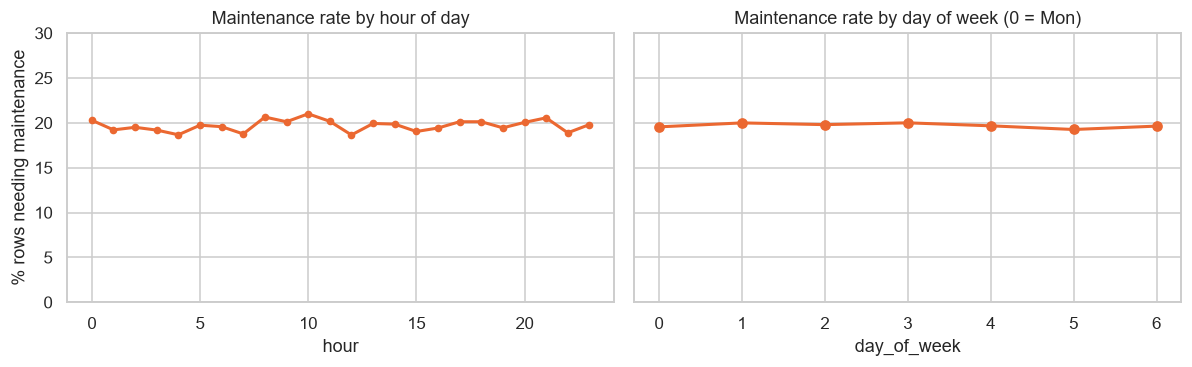

In [16]:
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
(df.groupby("hour")[TARGET].mean() * 100).plot(ax=axes[0], color=PALETTE[1], lw=2, marker="o", ms=4)
(df.groupby("day_of_week")[TARGET].mean() * 100).plot(ax=axes[1], color=PALETTE[1], lw=2, marker="o", ms=6)
axes[0].set_title("Maintenance rate by hour of day"); axes[1].set_title("Maintenance rate by day of week (0 = Mon)")
axes[0].set_ylabel("% rows needing maintenance")
for ax in axes: ax.set_ylim(0, 30)
plt.tight_layout(); plt.show()

In [17]:
# Is there a time pattern *within* each machine? If maintenance_required "runs" in streaks,
# consecutive readings of the same machine would agree more often than chance.
df_sorted = df.sort_values(["machine_id", "timestamp"])
same_as_prev = (df_sorted.groupby("machine_id")[TARGET].shift() == df_sorted[TARGET]).mean()
p = df[TARGET].mean()
print(f"Consecutive readings of a machine with the same label : {same_as_prev:.3f}")
print(f"Expected if readings were independent (p^2 + (1-p)^2): {p**2 + (1-p)**2:.3f}")

Consecutive readings of a machine with the same label : 0.686
Expected if readings were independent (p^2 + (1-p)^2): 0.684


<mark>Observation:</mark>
- There is exactly **one reading per minute** across the whole dataset (1 Jan 2025 → 11 Mar 2025, 100,000 unique timestamps). Each reading comes from one of the 50 machines, so each machine is sampled roughly every 50 minutes.
- The maintenance rate is **flat across hour of day and day of week** (it stays at about 19–21%).
- Consecutive readings of the same machine agree on the label **no more often than independent coin flips would** (0.686 vs 0.684 expected). There are no "streaks" leading up to maintenance.

<mark>Action:</mark> parse to datetime for analysis, but **do not use timestamp, hour or day-of-week as model features**. Also, **do not build rolling-window / lag features** (this is confirmed with mutual information in Section 7).

<mark>Justification:</mark> time features carry no signal, and adding them would only add noise and overfitting risk. Because each reading is independent of the previous one, a stratified random train/test split is acceptable. The data does not have the sequential leakage problem that would force a time-based split.

### 3.2 `machine_id`

Machines: 50


,count,mean,std,min,25%,50%,75%,max
readings,50.000,2000.000,51.673,1906.000,1956.250,2002.500,2042.500,2092.000
maintenance_rate,50.000,0.197,0.009,0.173,0.191,0.196,0.204,0.215


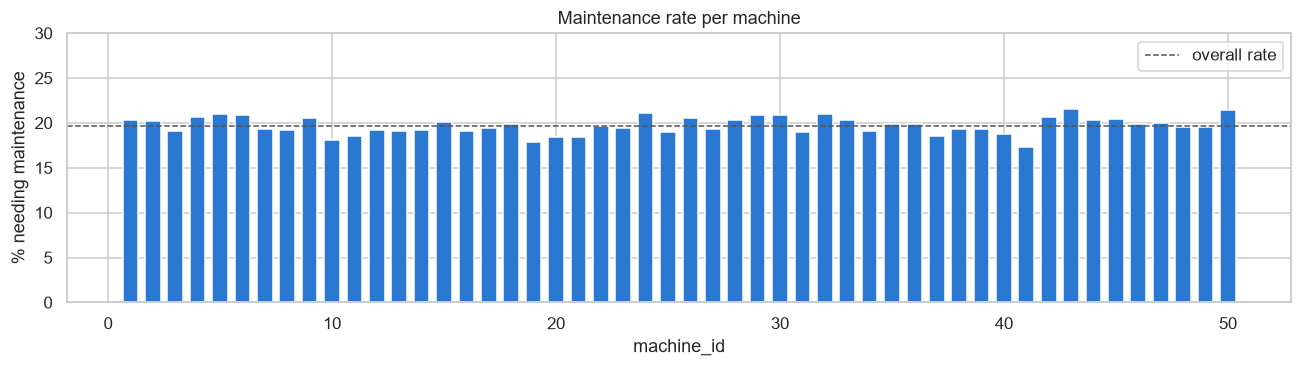

In [18]:
per_machine = df.groupby("machine_id")[TARGET].agg(readings="size", maintenance_rate="mean")
print("Machines:", df["machine_id"].nunique())
display(per_machine.describe().T)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(per_machine.index, per_machine["maintenance_rate"] * 100, color=PALETTE[0], width=0.7)
ax.axhline(df[TARGET].mean() * 100, color="#555", ls="--", lw=1, label="overall rate")
ax.set_xlabel("machine_id"); ax.set_ylabel("% needing maintenance"); ax.set_ylim(0, 30)
ax.set_title("Maintenance rate per machine"); ax.legend()
plt.tight_layout(); plt.show()

<mark>Observation:</mark> there are 50 machines with about 2,000 readings each (a balanced number of readings), and every machine's maintenance rate sits between **17.3% and 21.5%**. No machine is noticeably more failure-prone than the others.

<mark>Action:</mark> **exclude `machine_id` from the model features** (keep it only as an identifier for the alert output).

<mark>Justification:</mark> it is a nominal label. If it were used as an integer, models would treat it as a quantity. One-hot encoding it would add 50 sparse columns, even though the per-machine rates show it carries almost no information. Leaving it out also means the model can generalise to **new machines** that were not in the training data.

## 4. Sensor columns
### 4.1 `temperature` – nulls & outliers

In [19]:
temp_null = df["temperature"].isna()
print(f"Missing: {temp_null.sum():,} ({temp_null.mean():.1%})")
print("\nMissing rate by target:")
display(df.groupby(TARGET)["temperature"].apply(lambda s: s.isna().mean()).round(4))
print("Missing rate across machines: min {:.3f}, max {:.3f}".format(
    *df.groupby("machine_id")["temperature"].apply(lambda s: s.isna().mean()).agg(["min", "max"])))
print("\nCorrelation of temperature with the other sensors:")
display(df[SENSORS].corr()["temperature"].drop("temperature").round(3))

Missing: 14,000 (14.0%)

Missing rate by target:


maintenance_required
0   0.141
1   0.138
Name: temperature, dtype: float64

Missing rate across machines: min 0.126, max 0.157

Correlation of temperature with the other sensors:


vibration            -0.003
humidity              0.003
pressure             -0.001
energy_consumption    0.004
Name: temperature, dtype: float64

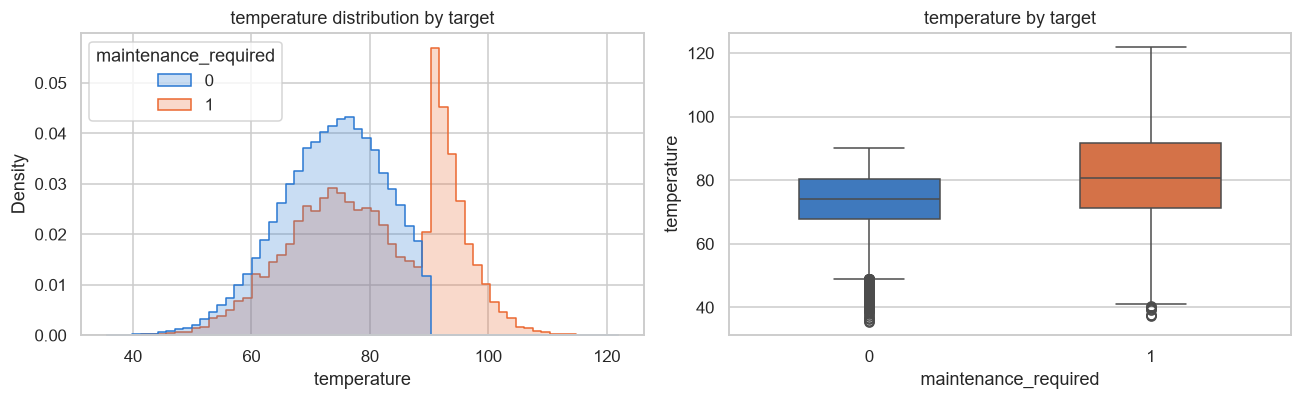

IQR outlier bounds: [48.03, 102.03]  ->  649 outliers


,rows,maintenance_rate
temperature,,
"(0, 60]",5747,13.800
"(60, 70]",20796,14.000
"(70, 80]",32796,13.800
"(80, 85]",12905,13.900
"(85, 90]",7924,14.300
"(90, 95]",3857,100.000
"(95, 130]",1975,100.000


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_hist_by_target(df, "temperature", axes[0], title="temperature distribution by target")
sns.boxplot(data=df, x=TARGET, y="temperature", hue=TARGET, palette=PALETTE, legend=False, ax=axes[1], width=0.5)
axes[1].set_title("temperature by target")
plt.tight_layout(); plt.show()

q1, q3 = df["temperature"].quantile([0.25, 0.75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"IQR outlier bounds: [{lo:.2f}, {hi:.2f}]  ->  {((df.temperature < lo) | (df.temperature > hi)).sum():,} outliers")
display(target_rate_by_bin(df, "temperature", [0, 60, 70, 80, 85, 90, 95, 130]))

<mark>Observation:</mark>
- **14% missing.** The missing rate is the same for both target classes (14.1% vs 13.8%) and for every machine, so the values appear to be **Missing Completely At Random**, which means the missingness itself does not predict maintenance.
- Temperature is **not correlated with any other sensor** (|r| < 0.01), so there is nothing to "borrow" from other columns to estimate it.
- The distribution is roughly normal (centred about 75 °C), with a long right tail.
- **Most important finding:** the maintenance rate is about 14–15% at every temperature up to 90 °C, then **jumps to about 100% above 90 °C**. The temperature signal works as a **threshold** rather than a gradual trend.
- The IQR rule marks hundreds of points as "outliers", but these high values are exactly the readings that need maintenance.

<mark>Action:</mark>
1. **Impute with the median** (computed on the training set only, inside the pipeline), and
2. add a binary **`temperature_missing`** indicator column so the model knows the value was imputed.
3. **Do not remove or cap the outliers.**

<mark>Justification:</mark>
- **Median rather than mean:** the right tail pulls the mean upwards, and the median is robust to it. Group-wise (per-machine) medians were considered, but all machines have nearly identical temperature distributions, so they would add complexity without changing the result.
- **KNN imputation is not useful** here, because temperature is uncorrelated with the other columns, so its "neighbours" would carry no information about it.
- **The outliers are the signal.** Removing them would remove the overheating cases the alert system exists to catch.
- **Limitation (to mention in the presentation):** an imputed value (about 75 °C) can never exceed the 90 °C threshold, so a machine that overheated during a reading with a missing temperature can only be caught through its vibration.

### 4.2 `vibration` – invalid negative values

In [21]:
neg = df["vibration"] < 0
print(f"Negative vibration readings: {neg.sum():,} ({neg.mean():.1%})")
compare = pd.DataFrame({
    "negative values (as |x|)": df.loc[neg, "vibration"].abs().describe(),
    "positive values": df.loc[~neg, "vibration"].describe(),
})
display(compare.T)
print("Maintenance rate – negative rows: {:.3f} | positive rows: {:.3f}".format(
    df.loc[neg, TARGET].mean(), df.loc[~neg, TARGET].mean()))

Negative vibration readings: 6,703 (6.7%)


,count,mean,std,min,25%,50%,75%,max
negative values (as |x|),6703.000,49.915,15.246,0.020,40.025,50.020,60.050,106.980
positive values,93297.000,50.023,14.954,0.100,39.960,49.960,60.110,113.800


Maintenance rate – negative rows: 0.196 | positive rows: 0.197


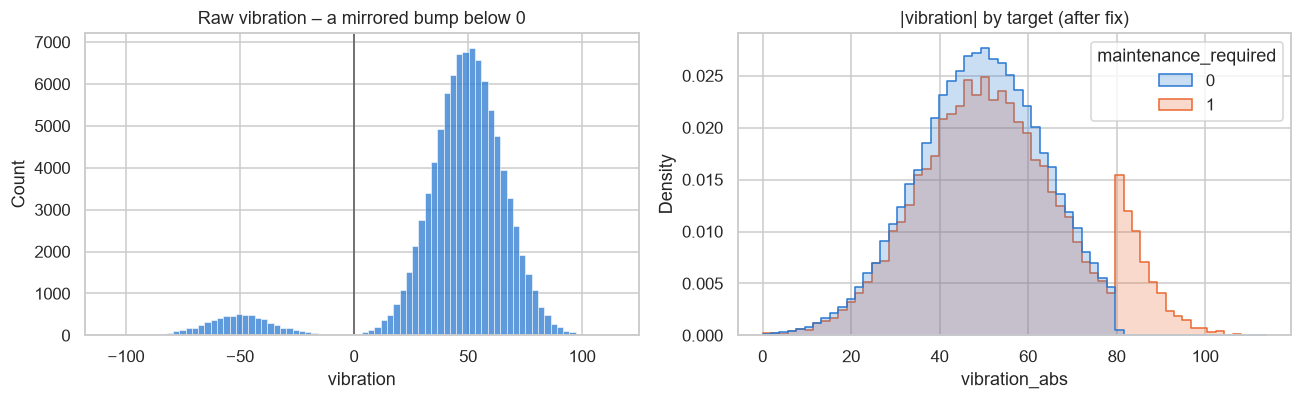

,rows,maintenance_rate
vibration_abs,,
"(0, 20]",2259,17.200
"(20, 40]",22809,17.800
"(40, 60]",49741,17.800
"(60, 70]",16026,17.800
"(70, 80]",6881,18.000
"(80, 90]",1905,100.000
"(90, 120]",379,100.000


In [22]:
df["vibration_abs"] = df["vibration"].abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df["vibration"], bins=80, color=PALETTE[0], ax=axes[0])
axes[0].axvline(0, color="#555", lw=1); axes[0].set_title("Raw vibration – a mirrored bump below 0")
plot_hist_by_target(df, "vibration_abs", axes[1], title="|vibration| by target (after fix)")
plt.tight_layout(); plt.show()

display(target_rate_by_bin(df, "vibration_abs", [0, 20, 40, 60, 70, 80, 90, 120]))

<mark>Observation:</mark>
- **6,703 readings (6.7%) are negative**, down to −106.98 mm/s. Vibration level is a magnitude, so a negative value is physically impossible.
- When the sign is flipped, the negative values have **almost the same distribution as the positive ones** (median about 50 vs about 48), and the same maintenance rate (19.6% vs 19.7%). The raw histogram shows a **mirror image** of the main bump below zero.
- As with temperature, vibration works as a **threshold**: the maintenance rate is about 18% up to 80 mm/s and **about 100% above 80 mm/s**.

<mark>Action:</mark> treat negatives as a **sign / data-entry error and take the absolute value** (`abs()`). Keep the high values.

<mark>Justification:</mark> the mirrored distribution and identical target rate show that these readings are real measurements with a lost sign, not random noise. Dropping them would throw away 6.7% of the data, including some genuine high-vibration (>80) alerts. This is the same reasoning as the negative `checkout_day` fix in the practical.

### 4.3 `humidity`, `pressure`, `energy_consumption`

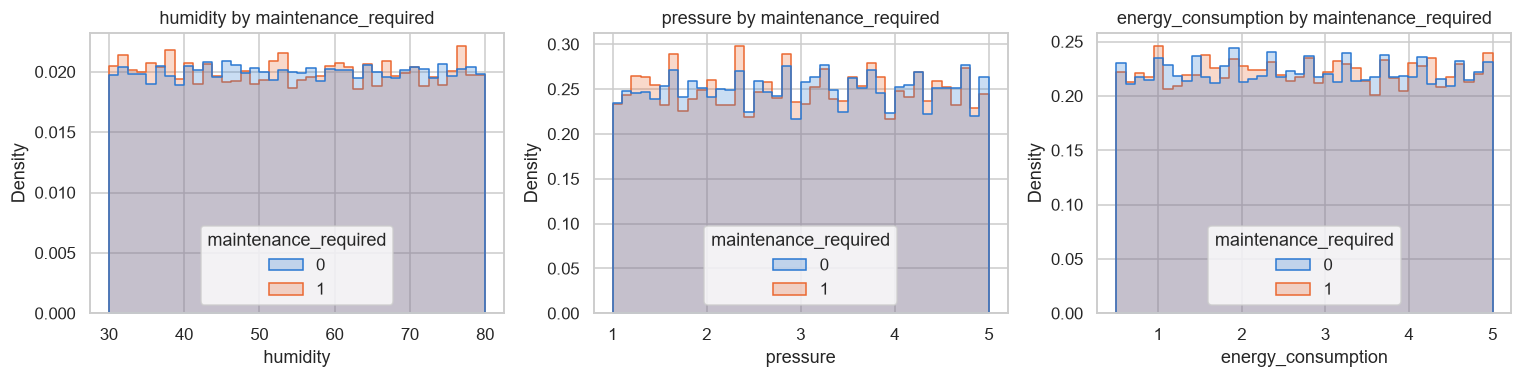

humidity             maintenance rate across quintiles: 19.2% – 20.3%
pressure             maintenance rate across quintiles: 19.5% – 19.9%
energy_consumption   maintenance rate across quintiles: 19.5% – 20.0%


In [23]:
others = ["humidity", "pressure", "energy_consumption"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, others):
    plot_hist_by_target(df, col, ax, bins=40)
plt.tight_layout(); plt.show()

for col in others:
    rates = df.groupby(pd.qcut(df[col], 5), observed=True)[TARGET].mean() * 100
    print(f"{col:<20} maintenance rate across quintiles: {rates.min():.1f}% – {rates.max():.1f}%")

<mark>Observation:</mark> all three columns are **uniformly distributed** (flat histograms) within valid ranges, with no nulls, invalid values or outliers. The two classes overlap almost perfectly, and the maintenance rate barely changes across quintiles.

<mark>Action:</mark> no cleaning is needed. **Keep them as features for now**, but expect low importance. Whether to drop them will be decided with feature importance during model development (Week 7).

<mark>Justification:</mark> removing a feature should be based on evidence from the model and not only on a plot, so we keep them for now. Even if they turn out useless, keeping them costs little with tree-based models. For distance-based models (such as logistic regression with scaling), uninformative features add noise, so feature selection will be revisited.

## 5. Derived columns – checking for target leakage
The problem statement says these are **derived** columns, so they were produced by some system and are not raw measurements. Before using them as features, we check how they relate to the target.

In [24]:
for col in ["machine_status", "anomaly_flag"]:
    print(f"--- {col} vs {TARGET}")
    display(pd.crosstab(df[col], df[TARGET], margins=True))

--- machine_status vs maintenance_required


maintenance_required,0,1,All
machine_status,,,
0,8776,1076,9852
1,71527,8564,80091
2,0,10057,10057
All,80303,19697,100000


--- anomaly_flag vs maintenance_required


maintenance_required,0,1,All
anomaly_flag,,,
0,80303,10781,91084
1,0,8916,8916
All,80303,19697,100000


<mark>Observation:</mark>
- **`machine_status == 2` (failure) → `maintenance_required` is 1 in 100% of rows** (10,057 / 10,057).
- **`anomaly_flag == 1` → `maintenance_required` is 1 in 100% of rows** (8,916 / 8,916).

In [18]:
# Is anomaly_flag just the temperature / vibration thresholds found in Section 4?
sensor_rule = (df["temperature"] > 90) | (df["vibration_abs"] > 80)
pd.crosstab(sensor_rule.rename("temp>90 or |vib|>80"), df["anomaly_flag"])

anomaly_flag,0,1
temp>90 or |vib|>80,,
False,91084,927
True,0,7989


`anomaly_flag` is essentially **"temperature > 90 or |vibration| > 80"**. Every row matching that rule is flagged. The 927 flagged rows outside the rule are the cases where the temperature reading is missing, so the rule cannot be checked from the data we have.

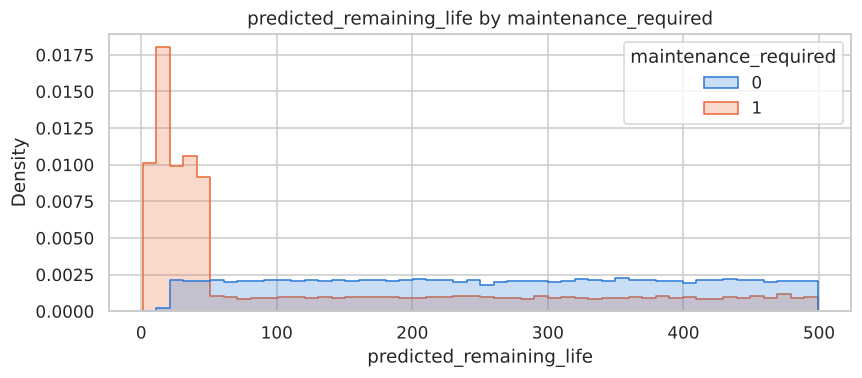

Maintenance rows not explained by status/anomaly: 1,648


count   1648.000
mean      14.387
std        2.868
min       10.000
25%       12.000
50%       14.000
75%       17.000
max       19.000
Name: predicted_remaining_life, dtype: float64

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.6))
plot_hist_by_target(df, "predicted_remaining_life", ax, bins=50)
plt.tight_layout(); plt.show()

# Rows that need maintenance but are NOT explained by failure or anomaly:
unexplained = df[(df[TARGET] == 1) & (df["machine_status"] != 2) & (df["anomaly_flag"] == 0)]
print(f"Maintenance rows not explained by status/anomaly: {len(unexplained):,}")
display(unexplained["predicted_remaining_life"].describe())

Every one of the 1,648 remaining maintenance rows has **`predicted_remaining_life` < 20 hours**. We now test the full rule:

In [20]:
rule = (df["machine_status"] == 2) | (df["anomaly_flag"] == 1) | (df["predicted_remaining_life"] < 20)
print(f"Rule accuracy vs maintenance_required: {(rule.astype(int) == df[TARGET]).mean():.4%}")
pd.crosstab(rule.rename("rule"), df[TARGET])

Rule accuracy vs maintenance_required: 100.0000%


maintenance_required,0,1
rule,,
False,80303,0
True,0,19697


In [21]:
display(pd.crosstab(df["failure_type"], df["machine_status"]))
print("\nAverage sensor readings per failure_type:")
display(df.groupby("failure_type")[["temperature", "vibration_abs", "pressure", "energy_consumption"]].mean())
print("\ndowntime_risk vs anomaly_flag:")
display(pd.crosstab(df["downtime_risk"].gt(0).rename("downtime_risk > 0"), df["anomaly_flag"]))

machine_status,0,1,2
failure_type,,,
Electrical Fault,0,0,1014
Normal,9852,80091,1956
Overheating,0,0,1989
Pressure Drop,0,0,1969
Vibration Issue,0,0,3129



Average sensor readings per failure_type:


,temperature,vibration_abs,pressure,energy_consumption
failure_type,,,,
Electrical Fault,75.463,48.970,2.987,2.795
Normal,75.021,50.027,3.001,2.747
Overheating,74.794,49.836,2.981,2.751
Pressure Drop,75.300,49.884,2.967,2.704
Vibration Issue,75.278,50.229,3.025,2.745



downtime_risk vs anomaly_flag:


anomaly_flag,0,1
downtime_risk > 0,,
False,91084,0
True,0,8916


<mark>Observation (the key finding of this EDA):</mark>

$$\texttt{maintenance\_required} = 1 \iff \texttt{machine\_status}=2 \;\lor\; \texttt{anomaly\_flag}=1 \;\lor\; \texttt{predicted\_remaining\_life} < 20$$

This rule reproduces the target with **100.00% accuracy on all 100,000 rows**. In addition:
- **`failure_type`** is non-"Normal" **only when `machine_status == 2`**, so it carries the same leaked information. The labels also **do not match the sensors**: "Overheating" machines are not hotter on average, and "Pressure Drop" machines do not have lower pressure. The column cannot be trusted as a description of the physical state.
- **`downtime_risk`** is > 0 exactly when `anomaly_flag == 1`, so it is a duplicate of `anomaly_flag`.

<mark>Action:</mark> **exclude all five derived columns from the main model's features**, and use only the raw sensor readings and the features engineered from them.

<mark>Justification:</mark>
- These columns are **outputs of the same monitoring logic that produced the label**, so any model given them would simply relearn the rule above (100% "accuracy" without predicting anything).
- `machine_status = 2` means the machine has **already failed**. The purpose of the alert system is to warn *before* a failure, so a feature that only exists after the failure is useless at prediction time.
- `predicted_remaining_life` is itself the **output of another model**. Using it would mean our model depends on a black box we cannot see.
- A model built on sensor readings answers the real question: *"can the readings tell us that this machine needs maintenance?"*

We will still train one "all columns" model in Section 8, **only to demonstrate the leakage** in the presentation.

## 6. Bivariate / multivariate analysis

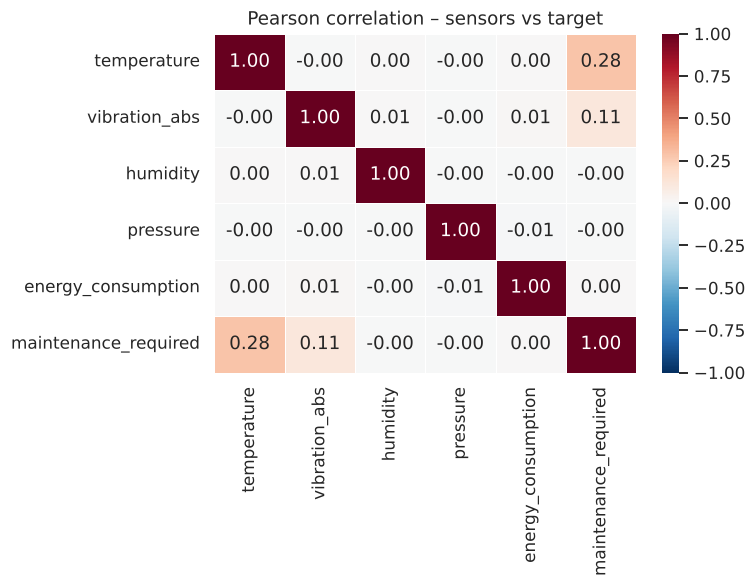

In [22]:
corr_cols = ["temperature", "vibration_abs", "humidity", "pressure", "energy_consumption", TARGET]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
ax.set_title("Pearson correlation – sensors vs target")
plt.tight_layout(); plt.show()

<mark>Observation:</mark> the sensors are **uncorrelated with each other** (no multicollinearity, so the independence assumption of logistic regression holds). Only temperature (0.28) and |vibration| (0.11) show any linear relationship with the target. The correlations are weak because the relationship is a **step**, not a straight line, and Pearson's r only measures linear relationships (as covered in the notes). The scatter plot below shows the step more clearly.

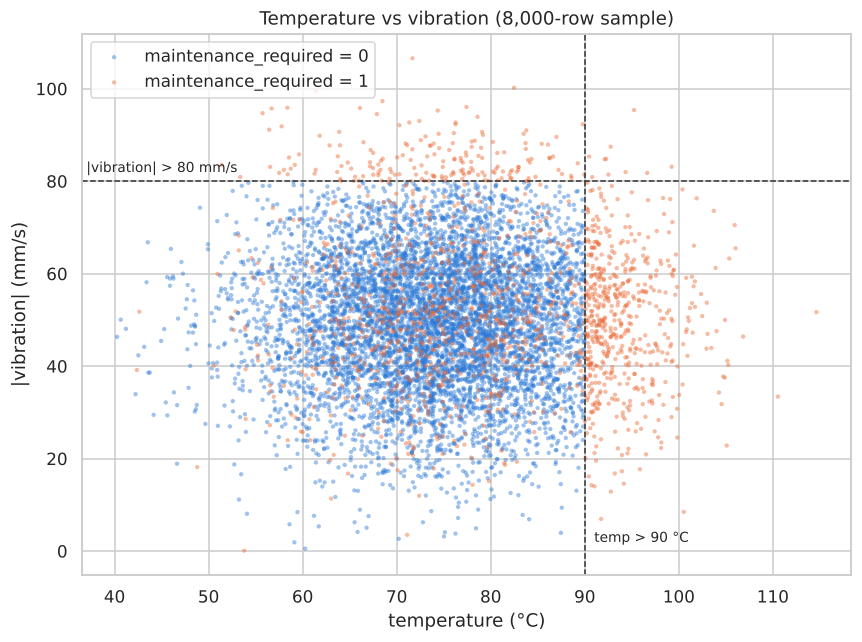

In [23]:
sample = df.dropna(subset=["temperature"]).sample(8000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 6))
for cls in [0, 1]:
    s = sample[sample[TARGET] == cls]
    ax.scatter(s["temperature"], s["vibration_abs"], s=8, alpha=0.45, color=PALETTE[cls],
               label=f"maintenance_required = {cls}", edgecolors="none")
ax.axvline(90, color="#333", ls="--", lw=1); ax.axhline(80, color="#333", ls="--", lw=1)
ax.text(91, 2, "temp > 90 °C", fontsize=9); ax.text(37, 82, "|vibration| > 80 mm/s", fontsize=9)
ax.set_xlabel("temperature (°C)"); ax.set_ylabel("|vibration| (mm/s)")
ax.set_title("Temperature vs vibration (8,000-row sample)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

<mark>Observation:</mark> this plot summarises the whole sensor story:
- Everything **right of 90 °C** or **above 80 mm/s** needs maintenance. That region is the anomaly area, and a model can learn it perfectly.
- **Inside the "normal" box, orange and blue points are completely mixed.** These are the maintenance cases caused by failure or low remaining life, and the sensors cannot tell them apart from healthy readings.

<mark>Implication for modelling:</mark>
- Tree-based models (Decision Tree / Random Forest / Gradient Boosting) can learn these axis-aligned thresholds directly.
- Logistic regression draws a single straight line, so it **cannot** represent an "L-shaped" region. It needs engineered threshold features (Section 7).
- There is a **ceiling on recall** for a sensor-only model, which we quantify in Section 8.

## 7. Feature engineering – candidates and evidence
We create candidate features and measure their **mutual information** with the target. Mutual information also captures non-linear relationships, unlike Pearson's r.

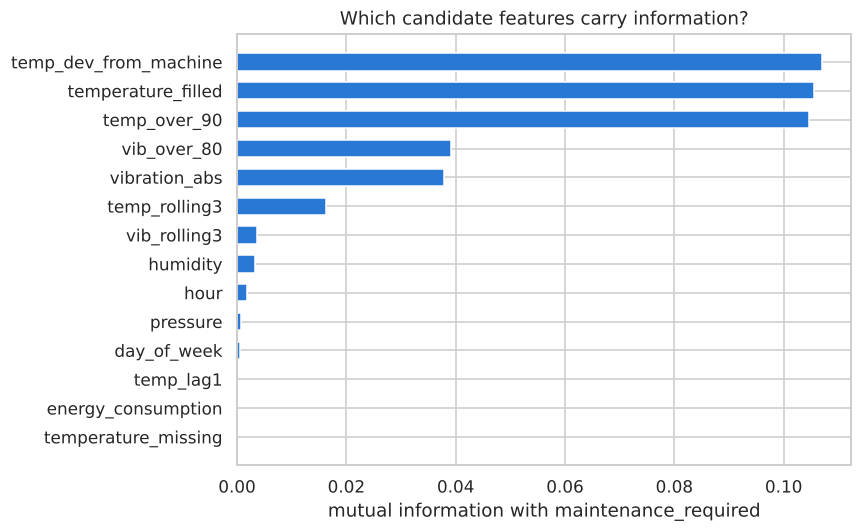

temp_dev_from_machine   0.107
temperature_filled      0.106
temp_over_90            0.105
vib_over_80             0.039
vibration_abs           0.038
temp_rolling3           0.016
vib_rolling3            0.004
humidity                0.003
hour                    0.002
pressure                0.001
day_of_week             0.001
temp_lag1               0.000
temperature_missing     0.000
energy_consumption      0.000
dtype: float64

In [24]:
fe = df.sort_values(["machine_id", "timestamp"]).copy()
fe["temperature_missing"] = fe["temperature"].isna().astype(int)
fe["temperature_filled"] = fe["temperature"].fillna(fe["temperature"].median())

# threshold features suggested by Sections 4 & 6
fe["temp_over_90"] = (fe["temperature_filled"] > 90).astype(int)
fe["vib_over_80"] = (fe["vibration_abs"] > 80).astype(int)

# per-machine features (does a machine's *own* history help?)
grp = fe.groupby("machine_id")
fe["temp_dev_from_machine"] = fe["temperature_filled"] - grp["temperature_filled"].transform("median")
fe["temp_rolling3"] = grp["temperature_filled"].transform(lambda s: s.rolling(3, min_periods=1).mean())
fe["vib_rolling3"] = grp["vibration_abs"].transform(lambda s: s.rolling(3, min_periods=1).mean())
fe["temp_lag1"] = grp["temperature_filled"].shift(1).fillna(fe["temperature_filled"].median())

candidates = ["temperature_filled", "vibration_abs", "humidity", "pressure", "energy_consumption",
              "temperature_missing", "temp_over_90", "vib_over_80",
              "temp_dev_from_machine", "temp_rolling3", "vib_rolling3", "temp_lag1", "hour", "day_of_week"]
sub = fe.sample(30000, random_state=RANDOM_STATE)
mi = pd.Series(mutual_info_classif(sub[candidates], sub[TARGET], random_state=RANDOM_STATE),
               index=candidates).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(mi.index, mi.values, color=PALETTE[0], height=0.6)
ax.set_xlabel("mutual information with maintenance_required")
ax.set_title("Which candidate features carry information?")
plt.tight_layout(); plt.show()
mi.sort_values(ascending=False).round(4)

<mark>Observation & decisions:</mark>

| Feature | Evidence | Decision |
|---|---|---|
| `temperature` (median-imputed) | highest MI | **Keep** |
| `vibration_abs` | 2nd highest MI | **Keep** (replaces raw `vibration`) |
| `temp_over_90`, `vib_over_80` | high MI, captures the step directly | **Keep**: these let **linear models** represent the threshold (binning, as in the notes: *"making linear models capture non-linearity"*). Trees can learn them on their own anyway. |
| `temperature_missing` | low MI (missing at random) | **Keep**: it tells the model that the imputed value is not a real reading, so the model can rely on vibration instead |
| `humidity`, `pressure`, `energy_consumption` | ≈ 0 | Keep for now and confirm with model feature importance |
| `temp_dev_from_machine` | ≈ same as raw temperature | **Drop**: machines behave identically, so it adds no new information |
| rolling means / lag | ≈ 0 | **Drop**: readings are independent over time (Section 3.1) |
| `hour`, `day_of_week` | ≈ 0 | **Drop** |

## 8. Quick baseline – demonstrating the leakage and the sensor-only ceiling
This is **not** the final model (that will be built in the `src/` pipeline). It is a quick check that the EDA conclusions hold up when a model is actually trained.

In [25]:
def quick_rf(X, y, label):
    """Train a default Random Forest on a stratified 80/20 split and return key class-1 metrics."""
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                                   n_jobs=-1, random_state=RANDOM_STATE).fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]; pred = (proba >= 0.5).astype(int)
    return {"features": label, "recall_1": recall_score(y_te, pred), "f1_1": f1_score(y_te, pred),
            "roc_auc": roc_auc_score(y_te, proba)}

sensor_feats = ["temperature_filled", "vibration_abs", "humidity", "pressure", "energy_consumption",
                "temperature_missing", "temp_over_90", "vib_over_80"]
leaky = fe[sensor_feats + ["machine_status", "anomaly_flag", "predicted_remaining_life", "downtime_risk"]]

results = pd.DataFrame([
    quick_rf(leaky, fe[TARGET], "sensors + derived columns (LEAKY)"),
    quick_rf(fe[sensor_feats], fe[TARGET], "sensors only"),
]).set_index("features")
results

,recall_1,f1_1,roc_auc
features,,,
sensors + derived columns (LEAKY),1.000,1.000,1.000
sensors only,0.420,0.564,0.714


In [26]:
# What share of maintenance cases is even *visible* in the sensor readings?
y1 = fe[fe[TARGET] == 1]
visible = ((y1["temperature"] > 90) | (y1["vibration_abs"] > 80)).mean()
print(f"Maintenance rows with temp > 90 or |vib| > 80: {visible:.1%}  <- approximate recall ceiling for sensor-only models")
print("\nWhy the rest are invisible – cause of maintenance among class-1 rows:")
cause = np.select([y1["anomaly_flag"] == 1, y1["machine_status"] == 2],
                  ["anomaly (visible in sensors)", "machine already failed"], "remaining life < 20 h")
display(pd.Series(cause).value_counts())

Maintenance rows with temp > 90 or |vib| > 80: 40.6%  <- approximate recall ceiling for sensor-only models

Why the rest are invisible – cause of maintenance among class-1 rows:


machine already failed          9133
anomaly (visible in sensors)    8916
remaining life < 20 h           1648
Name: count, dtype: int64

<mark>Observation:</mark>
- **With the derived columns, the model is essentially perfect** (recall and F1 of about 1.0), which confirms the leakage. That result would be impressive on a slide but means nothing in practice.
- **With sensors only**, the model is very **precise** when it raises an alert, but recall is capped at roughly **40–45%**. This is close to the share of maintenance cases that actually appear in the sensor readings. The rest come from machines that have **already failed** or from a low remaining-life estimate, and neither of those shows up in the sensor values at that moment.

<mark>Implication:</mark> this is a property of the data, not a weak model. Tuning in Week 7 should focus on:
1. getting as close as possible to that ceiling on recall, while keeping precision high,
2. adjusting the decision threshold (a lower threshold catches more cases but raises more false alarms), and
3. explaining this trade-off clearly in the README and the presentation.

## 9. Summary of EDA findings → pipeline decisions

| Column | Issue found | Pipeline action | Justification |
|---|---|---|---|
| `maintenance_required` | 80 / 20 imbalance | stratified split, `class_weight="balanced"` / oversampling on train only; main metrics **recall & F1 (class 1)**, plus PR-AUC | missing a machine that needs maintenance (false negative) = unscheduled downtime; accuracy is misleading |
| `timestamp` | stored as string; no time pattern | parse; **not a feature** | flat maintenance rate by hour and day; readings independent |
| `machine_id` | int but categorical; all machines alike | **not a feature** (identifier only) | no signal; generalises to new machines |
| `temperature` | 14% null (MCAR); right tail | **median impute (fit on train)** + `temperature_missing` flag; keep outliers | median robust to skew; KNN useless (no correlation with other sensors); outliers > 90 °C *are* the signal |
| `vibration` | 6.7% negative (invalid) | **`abs()`** | mirrored distribution & identical target rate → sign error |
| `humidity`, `pressure`, `energy_consumption` | clean, uniform, weak signal | keep; review with feature importance | remove features based on model evidence |
| `machine_status`, `anomaly_flag`, `predicted_remaining_life`, `failure_type`, `downtime_risk` | **reproduce the target 100%** | **exclude from features** (leakage demo only) | they come from the labelling logic / exist only after failure |
| *engineered* | — | `temp_over_90`, `vib_over_80`, `temperature_missing` | let linear models capture threshold behaviour |

**Candidate models (at least 3), chosen based on this EDA:**
1. **Logistic Regression** (with scaling + threshold features): an interpretable baseline. The sensors are not collinear, so its independence assumption holds.
2. **Random Forest**: learns threshold behaviour natively, is robust to outliers, needs no scaling, and provides feature importances.
3. **Gradient Boosting** (e.g. `HistGradientBoostingClassifier` / XGBoost): boosting gives more weight to the hard (minority) cases, which suits the class imbalance.

Tuning: `RandomizedSearchCV` / `GridSearchCV` with **stratified CV, scoring = recall or F1**, followed by decision-threshold tuning.